# 📊 Seaborn Tutorial Notebook




In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import datetime
sns.set_style('darkgrid')

In [2]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


## Load Dataset

In [3]:
df = sns.load_dataset('tips')
df.head()
#The tips dataset is a built-in sample dataset provided by Seaborn for practicing data visualization and analysis.
#It contains information about restaurant bills and tips given by customers.


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
df['smoker'].value_counts()

smoker
No     151
Yes     93
Name: count, dtype: int64

In [5]:
df.shape

(244, 7)

In [6]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

## Basic Plots

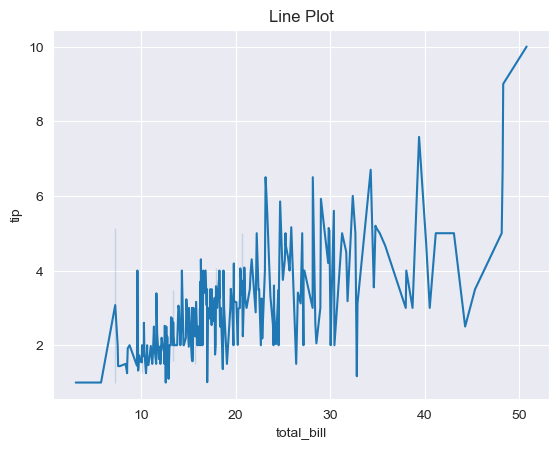

In [7]:
sns.lineplot(x='total_bill', y='tip', data=df)
plt.title('Line Plot')
plt.show()

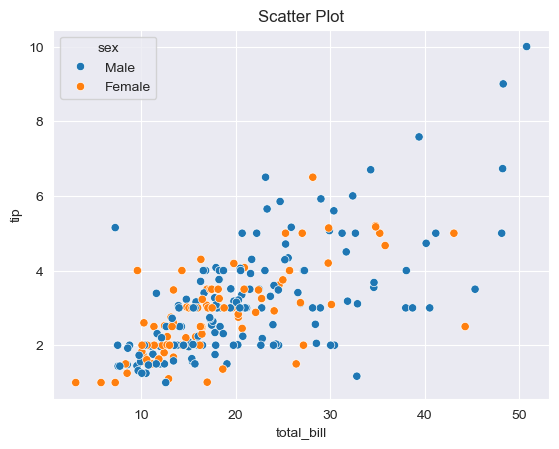

In [8]:
sns.scatterplot(x='total_bill', y='tip', hue='sex', data=df)#hue = grouping variable shown using different colors
plt.title('Scatter Plot')
plt.show()

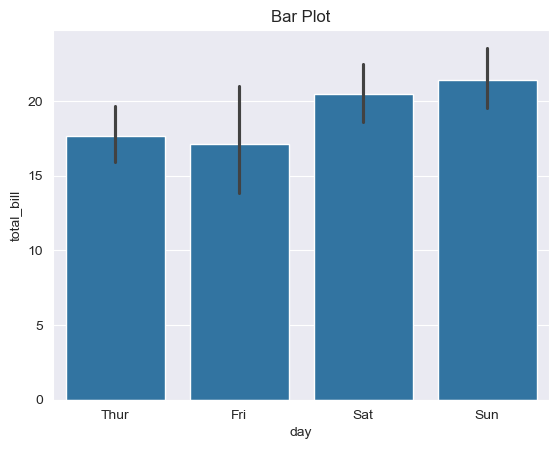

In [9]:
sns.barplot(x='day', y='total_bill', data=df)
plt.title('Bar Plot')
plt.show()

In Seaborn, the bar chart doesn’t just show values — it shows statistics.

What is an Error Bar?

It represents uncertainty or variation in the data

By default, Seaborn shows:

Mean (average) → height of bar

Confidence Interval (CI) → the line on top

What happens internally:

Groups data by day
Calculates mean total_bill
Draws:
Bar → mean value
Line → confidence interval

Why is this useful?

Because just showing the average is misleading sometimes.

Example:

Two days may have same average bill
But one has high variation, other has low variation

Error bars help you see that difference 

Interpretation
Small line → data is consistent
Large line → data varies a lot

C:\Users\Anju\AppData\Local\Temp\ipykernel_15180\3033568857.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='day', y='total_bill', data=df, ci=None)


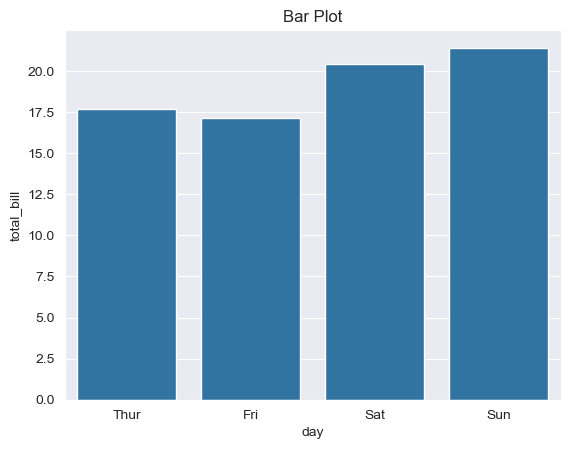

In [10]:
sns.barplot(x='day', y='total_bill', data=df, ci=None)
plt.title('Bar Plot')
plt.show()

## Distribution Plots

In Seaborn, histplot is used to show the distribution of numerical data using bars.

It divides data into bins (ranges) and counts how many values fall into each bin.


    X-axis → value ranges (bill amounts)
Y-axis → count (frequency)
Bars → how many values fall in each range

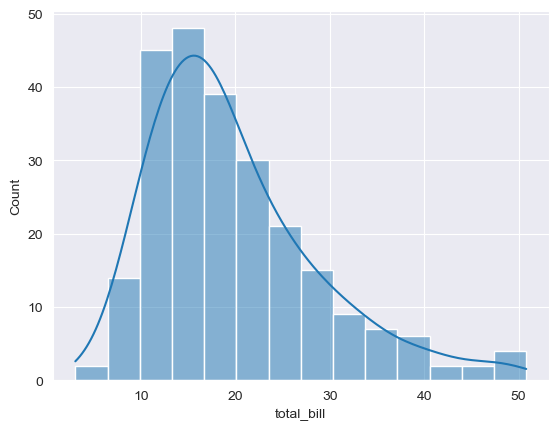

In [11]:
sns.histplot(df['total_bill'], kde=True)
plt.show()

What is KDE?

KDE = Kernel Density Estimation

It is a smooth curve that represents the probability density of the data.

Instead of bars, KDE shows a continuous curve

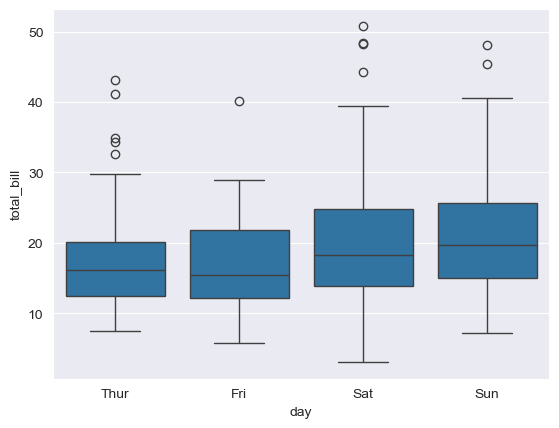

In [12]:
sns.boxplot(x='day', y='total_bill', data=df)
plt.show()

## Heatmap

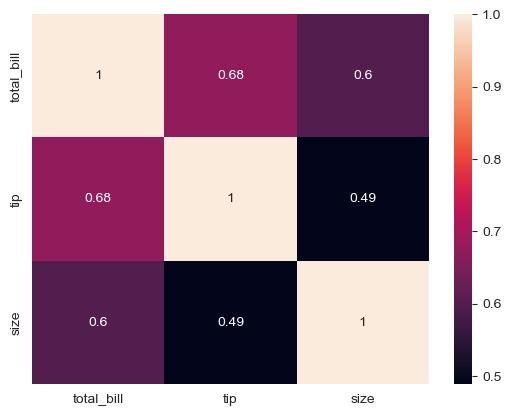

In [13]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True)#Shows numbers inside each box
plt.show()

Diagonal = 1 (same variable)
Symmetric matrix
Colors indicate strength:
Dark → strong
Light → weak

## Advanced Customization

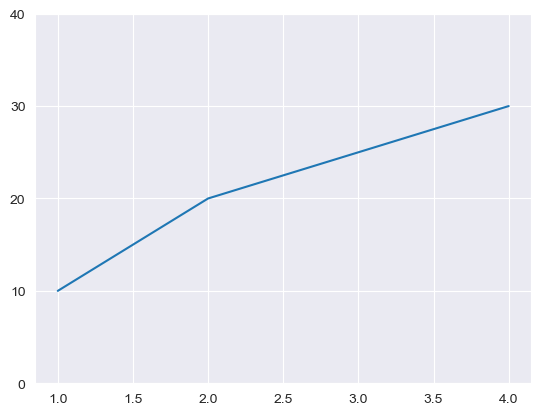

In [19]:
x = np.array([1,2,3,4])
y = np.array([10,20,25,30])

plt.plot(x, y)
# plt.xticks([1,2,3,4], ['Mon','Tue','Wed','Thu'])
plt.xticks()
plt.yticks([0,10,20,30,40])
plt.minorticks_on()
plt.show()

## Log Scale

[ 1.          1.18367347  1.36734694  1.55102041  1.73469388  1.91836735
  2.10204082  2.28571429  2.46938776  2.65306122  2.83673469  3.02040816
  3.20408163  3.3877551   3.57142857  3.75510204  3.93877551  4.12244898
  4.30612245  4.48979592  4.67346939  4.85714286  5.04081633  5.2244898
  5.40816327  5.59183673  5.7755102   5.95918367  6.14285714  6.32653061
  6.51020408  6.69387755  6.87755102  7.06122449  7.24489796  7.42857143
  7.6122449   7.79591837  7.97959184  8.16326531  8.34693878  8.53061224
  8.71428571  8.89795918  9.08163265  9.26530612  9.44897959  9.63265306
  9.81632653 10.        ]
[2.71828183e+00 3.26635103e+00 3.92492381e+00 4.71628026e+00
 5.66719268e+00 6.80983130e+00 8.18285258e+00 9.83270708e+00
 1.18152108e+01 1.41974337e+01 1.70599685e+01 2.04996572e+01
 2.46328676e+01 2.95994299e+01 3.55673674e+01 4.27385807e+01
 5.13556783e+01 6.17101843e+01 7.41524010e+01 8.91032597e+01
 1.07068561e+02 1.28656088e+02 1.54596164e+02 1.85766368e+02
 2.23221213e+02 2.6822783

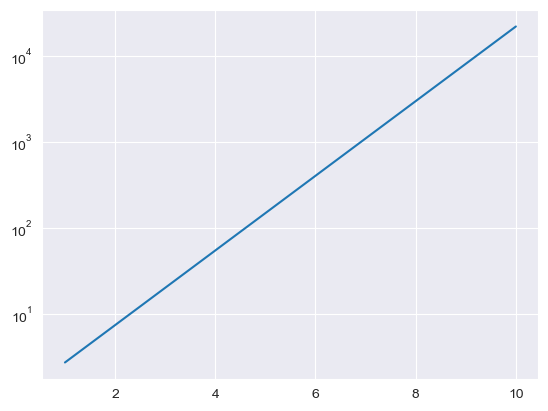

In [22]:
x = np.linspace(1,10,50)
y = np.exp(x)
print(x)
print(y)
plt.plot(x,y)
# plt.yscale('log')
plt.show()

## Time Series Plot

[datetime.datetime(2024, 1, 1, 0, 0), datetime.datetime(2024, 1, 2, 0, 0), datetime.datetime(2024, 1, 3, 0, 0), datetime.datetime(2024, 1, 4, 0, 0), datetime.datetime(2024, 1, 5, 0, 0)]


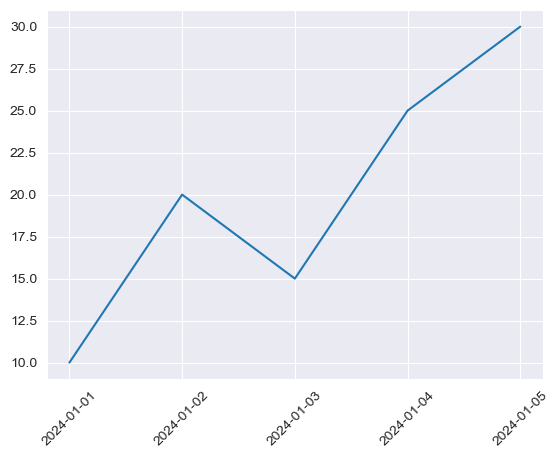

In [24]:
dates = [datetime.datetime(2024,1,i) for i in range(1,6)]
values = [10,20,15,25,30]
print(dates)
plt.plot(dates, values)
plt.xticks(dates,rotation=45)
plt.show()